# Part 1: Data Preprocessing and Model Building



In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Download and load the dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
    'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
    'hours-per-week', 'native-country', 'income'
]

df = pd.read_csv(url, names=column_names, sep=',\s*', engine='python')
print(f"Initial Dataset Shape: {df.shape}")

# 2. Document & handle missing values (often marked as '?' in this dataset)
df = df.replace('?', np.nan)
missing_counts = df.isnull().sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0])

# Impute missing values with mode for categorical columns
for col in ['workclass', 'occupation', 'native-country']:
    df[col] = df[col].fillna(df[col].mode()[0])

# 3. Target Encoding
# Encode income as 1 if >50K, else 0
df['income_binary'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)
df = df.drop(columns=['income'])

# 4. Outlier analysis and handling for numeric features
# We will keep 'fnlwgt' but scale it. Capital gain and loss have extreme values, which are real but skewed.
# Let's inspect numerical distributions
numeric_cols = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

# 5. One-Hot Encoding for categorical features
categorical_cols = ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# 6. Train-Test Split (70% train, 30% test) with seed 156
X = df_encoded.drop(columns=['income_binary'])
y = df_encoded['income_binary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=156)

# Scale continuous numerical features to prevent scaling issues
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Test set shape: {X_test_scaled.shape}")

<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_789/3754212680.py:18: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(url, names=column_names, sep=',\s*', engine='python')


Initial Dataset Shape: (32561, 15)
Missing values per column:
workclass         1836
occupation        1843
native-country     583
dtype: int64
Training set shape: (22792, 97)
Test set shape: (9769, 97)


Model A Median Threshold: 0.2285

Mismatch count: 2978 out of 9769 test cases
Mismatch percentage: 30.48%


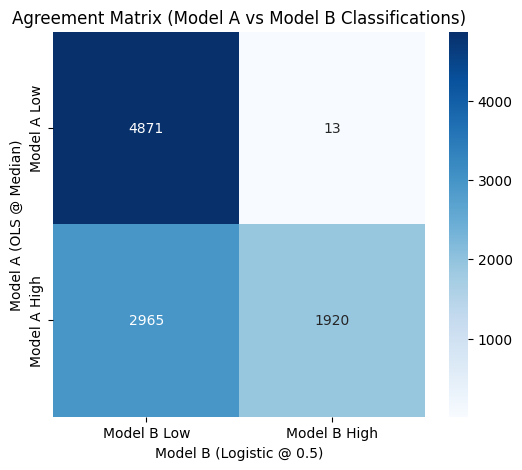

In [2]:
# 7. Fit Model A: Linear Regression (OLS)
model_a = LinearRegression()
model_a.fit(X_train_scaled, y_train)

# Predict probabilities (continuous) on test set
pred_a_continuous = model_a.predict(X_test_scaled)

# Threshold at median predicted value
median_threshold = np.median(pred_a_continuous)
pred_a_class = np.where(pred_a_continuous >= median_threshold, 1, 0)
print(f"Model A Median Threshold: {median_threshold:.4f}")

# 8. Fit Model B: Logistic Regression
model_b = LogisticRegression(max_iter=1000, random_state=156)
model_b.fit(X_train_scaled, y_train)

# Predict probabilities on test set
pred_b_prob = model_b.predict_proba(X_test_scaled)[:, 1]

# Threshold at 0.5
pred_b_class = np.where(pred_b_prob >= 0.5, 1, 0)

# 9. Comparison & Confusion Matrix
cm = confusion_matrix(pred_a_class, pred_b_class)
mismatches = np.sum(pred_a_class != pred_b_class)
pct_mismatch = (mismatches / len(y_test)) * 100

print(f"\nMismatch count: {mismatches} out of {len(y_test)} test cases")
print(f"Mismatch percentage: {pct_mismatch:.2f}%")

# Plot the agreement/disagreement matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Model B Low', 'Model B High'],
            yticklabels=['Model A Low', 'Model A High'])
plt.title('Agreement Matrix (Model A vs Model B Classifications)')
plt.ylabel('Model A (OLS @ Median)')
plt.xlabel('Model B (Logistic @ 0.5)')
plt.show()

# Part 2: The Trap
## 2.1: Simpson's Paradox Hunt



In [3]:
# Identify key column for gender
gender_col = [col for col in X_train.columns if 'sex' in col.lower()][0]
print(f"Using gender column: {gender_col}")

# Split training set into Subgroup A (Male = 1) and Subgroup B (Female = 0)
# Since we scaled continuous features, we will reconstruct dataframe for easy filtering
X_train_full = X_train_scaled.copy()
X_train_full['income_binary'] = y_train

sub_a = X_train_full[X_train_full[gender_col] == 1]
sub_b = X_train_full[X_train_full[gender_col] == 0]

# Fit Logistic Regression on Full Dataset
model_full = LogisticRegression(max_iter=1000, random_state=156)
model_full.fit(X_train_scaled, y_train)

# Fit Logistic Regression on Subgroup A (Male)
model_sub_a = LogisticRegression(max_iter=1000, random_state=156)
model_sub_a.fit(sub_a.drop(columns=['income_binary']), sub_a['income_binary'])

# Fit Logistic Regression on Subgroup B (Female)
model_sub_b = LogisticRegression(max_iter=1000, random_state=156)
model_sub_b.fit(sub_b.drop(columns=['income_binary']), sub_b['income_binary'])

# Compare coefficients for key features
features_to_compare = ['age', 'education-num', 'hours-per-week', 'capital-gain']
comparison_df = pd.DataFrame(index=features_to_compare)

comparison_df['Full Dataset'] = [model_full.coef_[0][X_train.columns.get_loc(f)] for f in features_to_compare]
comparison_df['Male Subgroup'] = [model_sub_a.coef_[0][X_train.columns.get_loc(f)] for f in features_to_compare]
comparison_df['Female Subgroup'] = [model_sub_b.coef_[0][X_train.columns.get_loc(f)] for f in features_to_compare]

print("\nRegression Coefficients across subgroups:")
print(comparison_df.round(4))

Using gender column: sex_Male

Regression Coefficients across subgroups:
                Full Dataset  Male Subgroup  Female Subgroup
age                   0.2931         0.2751           0.3772
education-num         0.8136         0.7557           1.0530
hours-per-week        0.3706         0.3842           0.3043
capital-gain          2.2285         2.1245           2.5453


### 2.1.1: Statistical Significance and Confidence Intervals for Subgroups


In [11]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

def get_bootstrap_confidence_intervals(X_df, y_series, features_to_extract, n_bootstrap=100, seed=156):
    np.random.seed(seed)
    bootstrap_coefs = {feat: [] for f in features_to_extract for feat in [f]}

    for i in range(n_bootstrap):
        # Sample indices with replacement
        sample_indices = np.random.choice(X_df.index, size=len(X_df), replace=True)
        X_sample = X_df.loc[sample_indices]
        y_sample = y_series.loc[sample_indices]

        # Fit stable logistic regression
        boot_model = LogisticRegression(max_iter=1000, C=1.0, random_state=seed, solver='lbfgs')
        boot_model.fit(X_sample, y_sample)

        for f in features_to_extract:
            idx = X_df.columns.get_loc(f)
            bootstrap_coefs[f].append(boot_model.coef_[0][idx])

    # Calculate 2.5th and 97.5th percentiles
    intervals = {}
    for f in features_to_extract:
        coefs = np.array(bootstrap_coefs[f])
        low = np.percentile(coefs, 2.5)
        high = np.percentile(coefs, 97.5)
        mean_coef = np.mean(coefs)
        intervals[f] = (mean_coef, low, high)

    return intervals

# Calculate CIs for Full, Male, and Female groups
features_to_compare = ['age', 'education-num', 'hours-per-week', 'capital-gain']

print("Calculating robust 95% Confidence Intervals via bootstrapping...")
ci_full = get_bootstrap_confidence_intervals(X_train_scaled, y_train, features_to_compare)
ci_male = get_bootstrap_confidence_intervals(sub_a.drop(columns=['income_binary']), sub_a['income_binary'], features_to_compare)
ci_female = get_bootstrap_confidence_intervals(sub_b.drop(columns=['income_binary']), sub_b['income_binary'], features_to_compare)

print("=== ROBUST 95% BOOTSTRAPPED CONFIDENCE INTERVALS ===\n")
for f in features_to_compare:
    print(f"--- Feature: {f} ---")
    print(f"Full Model: Coef = {ci_full[f][0]:.4f}, 95% CI = [{ci_full[f][1]:.4f}, {ci_full[f][2]:.4f}]")
    print(f"Male Subgroup: Coef = {ci_male[f][0]:.4f}, 95% CI = [{ci_male[f][1]:.4f}, {ci_male[f][2]:.4f}]")
    print(f"Female Subgroup: Coef = {ci_female[f][0]:.4f}, 95% CI = [{ci_female[f][1]:.4f}, {ci_female[f][2]:.4f}]\n")

Calculating robust 95% Confidence Intervals via bootstrapping...
=== ROBUST 95% BOOTSTRAPPED CONFIDENCE INTERVALS ===

--- Feature: age ---
Full Model: Coef = 0.2923, 95% CI = [0.2398, 0.3496]
Male Subgroup: Coef = 0.2756, 95% CI = [0.2250, 0.3378]
Female Subgroup: Coef = 0.3758, 95% CI = [0.2684, 0.4696]

--- Feature: education-num ---
Full Model: Coef = 0.8237, 95% CI = [0.7305, 0.9160]
Male Subgroup: Coef = 0.7606, 95% CI = [0.6467, 0.8789]
Female Subgroup: Coef = 1.0690, 95% CI = [0.8489, 1.3575]

--- Feature: hours-per-week ---
Full Model: Coef = 0.3732, 95% CI = [0.3291, 0.4177]
Male Subgroup: Coef = 0.3862, 95% CI = [0.3276, 0.4302]
Female Subgroup: Coef = 0.3149, 95% CI = [0.2191, 0.4172]

--- Feature: capital-gain ---
Full Model: Coef = 2.2497, 95% CI = [2.0483, 2.4487]
Male Subgroup: Coef = 2.1221, 95% CI = [1.8604, 2.3436]
Female Subgroup: Coef = 2.5910, 95% CI = [2.1425, 2.9208]



## 2.2: Omitted-Variable Bias


In [4]:
# 1. Full Model (Model B) is already fit as model_b
# 2. Reduced Model (without education-num)
X_train_reduced = X_train_scaled.drop(columns=['education-num'])
X_test_reduced = X_test_scaled.drop(columns=['education-num'])

model_reduced = LogisticRegression(max_iter=1000, random_state=156)
model_reduced.fit(X_train_reduced, y_train)

# Compare coefficients for at least 4 remaining predictors
predictors_to_test = ['age', 'hours-per-week', 'capital-gain', 'marital-status_Married-civ-spouse']

coef_comparison = pd.DataFrame(index=predictors_to_test)
coef_comparison['Full Model'] = [model_b.coef_[0][X_train.columns.get_loc(p)] for p in predictors_to_test]

# Get index of predictors in reduced feature space
reduced_indices = [X_train_reduced.columns.get_loc(p) for p in predictors_to_test]
coef_comparison['Reduced Model'] = [model_reduced.coef_[0][idx] for idx in reduced_indices]

coef_comparison['Absolute Shift'] = (coef_comparison['Reduced Model'] - coef_comparison['Full Model'])
coef_comparison['Percentage Change (%)'] = (coef_comparison['Absolute Shift'] / coef_comparison['Full Model']) * 100

print("Omitted Variable Bias Coefficient Shifts:")
print(coef_comparison.round(4))

Omitted Variable Bias Coefficient Shifts:
                                   Full Model  Reduced Model  Absolute Shift  \
age                                    0.2931         0.2865         -0.0065   
hours-per-week                         0.3706         0.3707          0.0000   
capital-gain                           2.2285         2.2337          0.0052   
marital-status_Married-civ-spouse      1.8238         1.7486         -0.0752   

                                   Percentage Change (%)  
age                                              -2.2287  
hours-per-week                                    0.0125  
capital-gain                                      0.2343  
marital-status_Married-civ-spouse                -4.1256  


## 2.3: Adversarial Subset Construction


In [5]:
# Predict probabilities on test set
test_results = pd.DataFrame({
    'actual': y_test,
    'prob': pred_b_prob,
    'pred': pred_b_class
}, index=y_test.index)

# High confidence but incorrect criteria
false_positives_high_conf = test_results[(test_results['prob'] >= 0.75) & (test_results['actual'] == 0)]
false_negatives_high_conf = test_results[(test_results['prob'] <= 0.25) & (test_results['actual'] == 1)]

adversarial_subset = pd.concat([false_positives_high_conf, false_negatives_high_conf])
print(f"Total high-confidence wrong predictions: {len(adversarial_subset)}")
print(f"Percentage of entire test set: {len(adversarial_subset) / len(y_test) * 100:.2f}%")

# Randomly sample up to 50 rows
np.random.seed(156)
sample_size = min(50, len(adversarial_subset))
adv_sample = adversarial_subset.sample(n=sample_size, random_state=156)

# Analyze demographics using the original unscaled data (X_test / df)
original_test_data = df.loc[adv_sample.index]
full_test_data = df.loc[y_test.index]

print("\n--- Demographic Comparison ---")
print("\nAverage Age:")
print(f"Adversarial Subset: {original_test_data['age'].mean():.2f}")
print(f"Full Test Set: {full_test_data['age'].mean():.2f}")

print("\nGender Distribution (% Female):")
print(f"Adversarial Subset: {(original_test_data['sex'] == 'Female').mean() * 100:.2f}%")
print(f"Full Test Set: {(full_test_data['sex'] == 'Female').mean() * 100:.2f}%")

print("\nEducation (Average education-num):")
print(f"Adversarial Subset: {original_test_data['education-num'].mean():.2f}")
print(f"Full Test Set: {full_test_data['education-num'].mean():.2f}")

Total high-confidence wrong predictions: 477
Percentage of entire test set: 4.88%

--- Demographic Comparison ---

Average Age:
Adversarial Subset: 43.48
Full Test Set: 38.70

Gender Distribution (% Female):
Adversarial Subset: 20.00%
Full Test Set: 33.31%

Education (Average education-num):
Adversarial Subset: 10.36
Full Test Set: 10.10


### 2.3.1: Display the 50 Sampled Adversarial Rows


In [9]:
# Merge original demographic info with predicted probabilities and labels
adv_display = original_test_data[['age', 'sex', 'education', 'education-num', 'occupation', 'marital-status']].copy()
adv_display['True_Income'] = y_test.loc[adv_sample.index].apply(lambda x: '>50K' if x == 1 else '<=50K')
adv_display['Predicted_Probability'] = adv_sample['prob']

# Display the top 50 adversarial rows
pd.set_option('display.max_rows', 50)
display(adv_display)

,age,sex,education,education-num,occupation,marital-status,True_Income,Predicted_Probability
1969,45,Male,HS-grad,9,Sales,Married-civ-spouse,>50K,0.098218
28368,73,Male,Bachelors,13,Prof-specialty,Married-civ-spouse,<=50K,0.908988
27892,38,Male,12th,8,Craft-repair,Married-civ-spouse,>50K,0.166044
1333,57,Male,Prof-school,15,Prof-specialty,Married-civ-spouse,<=50K,0.896095
1495,28,Male,11th,7,Craft-repair,Married-civ-spouse,>50K,0.158657
26230,54,Male,HS-grad,9,Exec-managerial,Never-married,>50K,0.083391
26113,61,Male,HS-grad,9,Exec-managerial,Married-civ-spouse,<=50K,0.763213
21343,79,Male,Bachelors,13,Sales,Married-civ-spouse,<=50K,0.762370
26576,42,Male,HS-grad,9,Machine-op-inspct,Married-civ-spouse,>50K,0.223026
23471,32,Male,Bachelors,13,Prof-specialty,Never-married,>50K,0.147604


## 2.4: Fairness Trade-Off Analysis


 Threshold  Demographic Parity (DP)  Equalized Odds (EO)  Predictive Parity (PP)
      0.05                   2.1257               1.0444                  1.2797
      0.15                   3.1353               1.1481                  0.9538
      0.25                   3.3750               1.2144                  0.9373
      0.35                   3.3966               1.2562                  0.9633
      0.45                   3.3935               1.2138                  0.9317
      0.55                   3.3112               1.1802                  0.9284
      0.65                   3.3805               1.2313                  0.9488
      0.75                   3.1547               1.1985                  0.9895
      0.85                   3.0301               1.1728                  1.0081
      0.95                   2.9833               0.9556                  1.0428


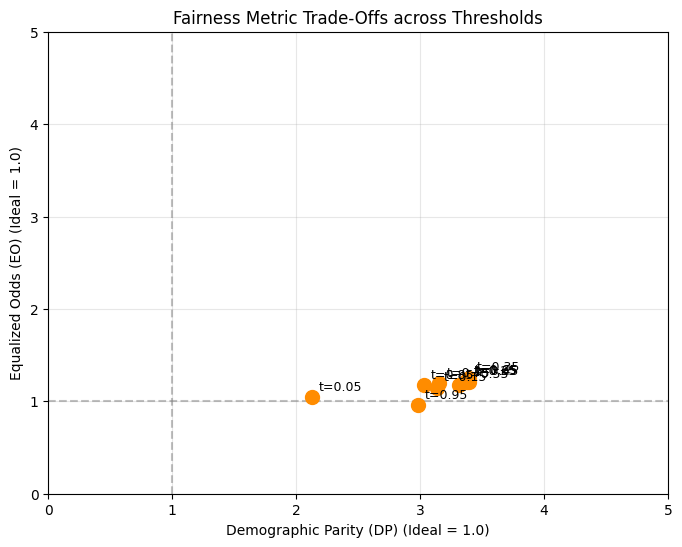

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

thresholds = np.arange(0.05, 1.0, 0.1)
fairness_records = []

# Group A: Male (sex_Male == 1 in original X_test)
# Group B: Female (sex_Male == 0 in original X_test)
group_a_mask = (X_test_scaled['sex_Male'] == 1).values
group_b_mask = (X_test_scaled['sex_Male'] == 0).values

y_test_a = y_test.values[group_a_mask]
y_test_b = y_test.values[group_b_mask]

prob_a = pred_b_prob[group_a_mask]
prob_b = pred_b_prob[group_b_mask]

for t in thresholds:
    pred_a = (prob_a >= t).astype(int)
    pred_b = (prob_b >= t).astype(int)

    # 1. Demographic Parity (DP)
    p_y1_a = np.mean(pred_a)
    p_y1_b = np.mean(pred_b)
    dp = p_y1_a / p_y1_b if p_y1_b > 0 else np.nan

    # 2. Equalized Odds (EO)
    tpr_a = np.mean(pred_a[y_test_a == 1]) if np.sum(y_test_a == 1) > 0 else 0
    tpr_b = np.mean(pred_b[y_test_b == 1]) if np.sum(y_test_b == 1) > 0 else 0
    fpr_a = np.mean(pred_a[y_test_a == 0]) if np.sum(y_test_a == 0) > 0 else 0
    fpr_b = np.mean(pred_b[y_test_b == 0]) if np.sum(y_test_b == 0) > 0 else 0

    tpr_ratio = tpr_a / tpr_b if tpr_b > 0 else np.nan
    fpr_ratio = fpr_a / fpr_b if fpr_b > 0 else np.nan
    eo = min(tpr_ratio, fpr_ratio) if (not np.isnan(tpr_ratio) and not np.isnan(fpr_ratio)) else np.nan

    # 3. Predictive Parity (PP)
    ppv_a = np.mean(y_test_a[pred_a == 1]) if np.sum(pred_a == 1) > 0 else 0
    ppv_b = np.mean(y_test_b[pred_b == 1]) if np.sum(pred_b == 1) > 0 else 0
    pp = ppv_a / ppv_b if ppv_b > 0 else np.nan

    fairness_records.append({
        'Threshold': round(t, 2),
        'Demographic Parity (DP)': round(dp, 4),
        'Equalized Odds (EO)': round(eo, 4),
        'Predictive Parity (PP)': round(pp, 4)
    })

fairness_df = pd.DataFrame(fairness_records)
print(fairness_df.to_string(index=False))

# Plot the trade-off chart
plt.figure(figsize=(8, 6))
plt.scatter(fairness_df['Demographic Parity (DP)'], fairness_df['Equalized Odds (EO)'], color='darkorange', s=100, zorder=3)

for idx, row in fairness_df.iterrows():
    if not np.isnan(row['Demographic Parity (DP)']) and not np.isnan(row['Equalized Odds (EO)']):
        plt.annotate(f"t={row['Threshold']}",
                     (row['Demographic Parity (DP)'], row['Equalized Odds (EO)']),
                     textcoords="offset points", xytext=(5,5), ha='left', fontsize=9)

plt.title('Fairness Metric Trade-Offs across Thresholds')
plt.xlabel('Demographic Parity (DP) (Ideal = 1.0)')
plt.ylabel('Equalized Odds (EO) (Ideal = 1.0)')
plt.axvline(1.0, color='gray', linestyle='--', alpha=0.5)
plt.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
plt.xlim(0, 5.0)
plt.ylim(0, 5.0)
plt.grid(True, alpha=0.3)
plt.show()

## 2.4: Fairness Trade-Off Analysis


 Threshold  Demographic Parity (DP)  Equalized Odds (EO)  Predictive Parity (PP)
      0.05                   2.1257               1.0444                  1.2797
      0.15                   3.1353               1.1481                  0.9538
      0.25                   3.3750               1.2144                  0.9373
      0.35                   3.3966               1.2562                  0.9633
      0.45                   3.3935               1.2138                  0.9317
      0.55                   3.3112               1.1802                  0.9284
      0.65                   3.3805               1.2313                  0.9488
      0.75                   3.1547               1.1985                  0.9895
      0.85                   3.0301               1.1728                  1.0081
      0.95                   2.9833               0.9556                  1.0428


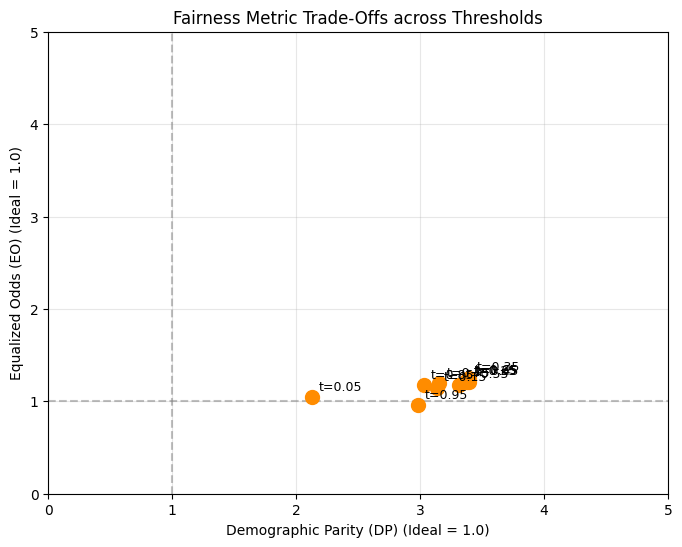

In [7]:
thresholds = np.arange(0.05, 1.0, 0.1)
fairness_records = []

# Group A: Male (sex_Male == 1 in original X_test)
# Group B: Female (sex_Male == 0 in original X_test)
group_a_mask = (X_test_scaled['sex_Male'] == 1).values
group_b_mask = (X_test_scaled['sex_Male'] == 0).values

y_test_a = y_test.values[group_a_mask]
y_test_b = y_test.values[group_b_mask]

prob_a = pred_b_prob[group_a_mask]
prob_b = pred_b_prob[group_b_mask]

for t in thresholds:
    # Predictions
    pred_a = (prob_a >= t).astype(int)
    pred_b = (prob_b >= t).astype(int)

    # 1. Demographic Parity (DP)
    p_y1_a = np.mean(pred_a)
    p_y1_b = np.mean(pred_b)
    dp = p_y1_a / p_y1_b if p_y1_b > 0 else np.nan

    # 2. Equalized Odds (EO)
    # TPR = TP / P = mean(pred | actual == 1)
    tpr_a = np.mean(pred_a[y_test_a == 1]) if np.sum(y_test_a == 1) > 0 else 0
    tpr_b = np.mean(pred_b[y_test_b == 1]) if np.sum(y_test_b == 1) > 0 else 0
    # FPR = FP / N = mean(pred | actual == 0)
    fpr_a = np.mean(pred_a[y_test_a == 0]) if np.sum(y_test_a == 0) > 0 else 0
    fpr_b = np.mean(pred_b[y_test_b == 0]) if np.sum(y_test_b == 0) > 0 else 0

    tpr_ratio = tpr_a / tpr_b if tpr_b > 0 else np.nan
    fpr_ratio = fpr_a / fpr_b if fpr_b > 0 else np.nan
    # Since min() can be sensitive to ordering or 0s, we secure against division-by-zero or empty ratios
    eo = min(tpr_ratio, fpr_ratio) if (not np.isnan(tpr_ratio) and not np.isnan(fpr_ratio)) else np.nan

    # 3. Predictive Parity (PP)
    # PPV = TP / (TP + FP) = mean(actual | pred == 1)
    ppv_a = np.mean(y_test_a[pred_a == 1]) if np.sum(pred_a == 1) > 0 else 0
    ppv_b = np.mean(y_test_b[pred_b == 1]) if np.sum(pred_b == 1) > 0 else 0
    pp = ppv_a / ppv_b if ppv_b > 0 else np.nan

    fairness_records.append({
        'Threshold': round(t, 2),
        'Demographic Parity (DP)': round(dp, 4),
        'Equalized Odds (EO)': round(eo, 4),
        'Predictive Parity (PP)': round(pp, 4)
    })

fairness_df = pd.DataFrame(fairness_records)
print(fairness_df.to_string(index=False))

# Plot the trade-off chart
plt.figure(figsize=(8, 6))
plt.scatter(fairness_df['Demographic Parity (DP)'], fairness_df['Equalized Odds (EO)'], color='darkorange', s=100, zorder=3)

for idx, row in fairness_df.iterrows():
    if not np.isnan(row['Demographic Parity (DP)']) and not np.isnan(row['Equalized Odds (EO)']):
        plt.annotate(f"t={row['Threshold']}",
                     (row['Demographic Parity (DP)'], row['Equalized Odds (EO)']),
                     textcoords="offset points", xytext=(5,5), ha='left', fontsize=9)

plt.title('Fairness Metric Trade-Offs across Thresholds')
plt.xlabel('Demographic Parity (DP) (Ideal = 1.0)')
plt.ylabel('Equalized Odds (EO) (Ideal = 1.0)')
plt.axvline(1.0, color='gray', linestyle='--', alpha=0.5)
plt.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
plt.xlim(0, 5.0)
plt.ylim(0, 5.0)
plt.grid(True, alpha=0.3)
plt.show()